In [ ]:
### This is where VegFormer actually learns.

In [1]:
import torch
import numpy as np
import pickle
import sys
import json
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

sys.path.append('C:/vegformer')
from models.vegformer import build_vegformer, MaskedSensorModeling

PROCESSED_DIR = Path('C:/vegformer/data/processed')
PATCHES_DIR   = Path('C:/vegformer/data/patches')
CKPT_DIR      = Path('C:/vegformer/checkpoints')
CKPT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load train patches
with open(PATCHES_DIR / 'train_patches.pkl', 'rb') as f:
    train_patches = pickle.load(f)

print(f"Device:        {device}")
print(f"Train patches: {len(train_patches)}")
print(f"T per patch:   {train_patches[0]['s2'].shape[0]}")
print(f"S2 shape:      {train_patches[0]['s2'].shape}")
print(f"S1 shape:      {train_patches[0]['s1'].shape}")
print(f"CHIRPS shape:  {train_patches[0]['chirps'].shape}")
print(f"Ready for MSM pre-training")

Device:        cpu
Train patches: 80
T per patch:   109
S2 shape:      (109, 14, 64, 64)
S1 shape:      (109, 2, 64, 64)
CHIRPS shape:  (109, 4)
Ready for MSM pre-training


In [ ]:
####Device:Build the Dataset and model for pre-training

In [3]:
# Fix mask token sizes in vegformer.py
vegformer_path = 'C:/vegformer/models/vegformer.py'

with open(vegformer_path, 'r') as f:
    code = f.read()

# Fix optical mask token size 12 -> 14
code = code.replace(
    'self.optical_mask = nn.Parameter(torch.zeros(1, 1, 12))',
    'self.optical_mask = nn.Parameter(torch.zeros(1, 1, 14))'
)

with open(vegformer_path, 'w') as f:
    f.write(code)

print("Fixed optical mask token size 12 -> 14")

# Reload module
import importlib
import sys
for mod in list(sys.modules.keys()):
    if 'vegformer' in mod:
        del sys.modules[mod]

from models.vegformer import build_vegformer, MaskedSensorModeling

# Rebuild
model = build_vegformer({
    'n_bands':        14,
    'n_climate_vars': 4,
    'd_model':        384,
    'n_heads':        8,
    'n_layers':       4,
    'n_veg_classes':  8,
    'n_deg_classes':  4,
    'dropout':        0.1,
    'max_seq_len':    137,
}).to(device)

msm = MaskedSensorModeling(model, mask_ratio=0.4).to(device)

# Retest
model.eval()
batch = next(iter(train_loader))
model_input = {
    'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
    'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
    'climate': batch['chirps'].to(device),
    'dates':   batch['julian_days'].to(device),
}
with torch.no_grad():
    msm_out = msm(model_input)

print(f"MSM test forward pass:")
print(f"  Loss:  {msm_out['loss'].item():.4f}")
print(f"  Mask:  {msm_out['mask'].float().mean().item()*100:.1f}% timesteps masked")
print(f"  Recon: {msm_out['recon'].shape}")
print(f"\nReady to train")

Fixed optical mask token size 12 -> 14


C:\vegformer\models\vegformer.py:120: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.temporal_attn = nn.TransformerEncoder(encoder_layer, num_layers=2)
C:\vegformer\models\vegformer.py:148: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
C:\vegformer\models\vegformer.py:296: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)


MSM test forward pass:
  Loss:  1.0578
  Mask:  77.1% timesteps masked
  Recon: torch.Size([4, 109, 20])

Ready to train


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader

class MaraDataset(Dataset):
    def __init__(self, patches):
        self.patches = patches

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        p = self.patches[idx]
        return {
            's2':          torch.tensor(p['s2'],          dtype=torch.float32),
            's1':          torch.tensor(p['s1'],          dtype=torch.float32),
            'chirps':      torch.tensor(p['chirps'],      dtype=torch.float32),
            'julian_days': torch.tensor(p['julian_days'], dtype=torch.float32),
        }

train_ds     = MaraDataset(train_patches)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)

print(f"Train dataset:  {len(train_ds)} patches")
print(f"Train batches:  {len(train_loader)}")

# Build model
model = build_vegformer({
    'n_bands':        14,
    'n_climate_vars': 4,
    'd_model':        384,
    'n_heads':        8,
    'n_layers':       4,
    'n_veg_classes':  8,
    'n_deg_classes':  4,
    'dropout':        0.1,
    'max_seq_len':    137,
}).to(device)

# Wrap in MSM
msm = MaskedSensorModeling(model, mask_ratio=0.4).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"VegFormer parameters: {n_params:,}")

# Test one MSM forward pass before training
model.eval()
batch = next(iter(train_loader))
model_input = {
    'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
    'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
    'climate': batch['chirps'].to(device),
    'dates':   batch['julian_days'].to(device),
}
with torch.no_grad():
    msm_out = msm(model_input)

print(f"\nMSM test forward pass:")
print(f"  Loss:  {msm_out['loss'].item():.4f}")
print(f"  Mask:  {msm_out['mask'].float().mean().item()*100:.1f}% timesteps masked")
print(f"  Recon: {msm_out['recon'].shape}")
print(f"\nReady to train")

Train dataset:  80 patches
Train batches:  20
VegFormer parameters: 8,919,393

MSM test forward pass:
  Loss:  0.8632
  Mask:  78.2% timesteps masked
  Recon: torch.Size([4, 109, 20])

Ready to train


In [ ]:
###Full pre-training loop
#### Loss 0.8632 is expected for an untrained model
#####Mask 78.2% is higher than our target 40% — the three modality masks are combining. 
###### We'll fix that during training

In [5]:
import time

# Fix mask ratio — current 78% is too high, reduce per-modality ratio
msm = MaskedSensorModeling(model, mask_ratio=0.2).to(device)  # 0.2 per sensor ≈ 40% overall

optimizer = torch.optim.AdamW(
    msm.parameters(), lr=1e-4, weight_decay=0.05
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=30
)

best_loss = float('inf')
history   = []

print("Starting MSM pre-training — 30 epochs")
print(f"Batches per epoch: {len(train_loader)}")
print("-" * 50)

for epoch in range(30):
    msm.train()
    epoch_loss = 0.0
    t0 = time.time()

    for batch in train_loader:
        model_input = {
            'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
            'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
            'climate': batch['chirps'].to(device),
            'dates':   batch['julian_days'].to(device),
        }
        optimizer.zero_grad()
        out  = msm(model_input)
        loss = out['loss']
        loss.backward()
        torch.nn.utils.clip_grad_norm_(msm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    scheduler.step()
    elapsed = time.time() - t0
    history.append(epoch_loss)

    print(f"Epoch {epoch+1:2d}/30 | "
          f"loss={epoch_loss:.4f} | "
          f"lr={scheduler.get_last_lr()[0]:.2e} | "
          f"{elapsed:.0f}s")

    # Save best checkpoint
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        torch.save({
            'epoch':       epoch,
            'model_state': model.state_dict(),
            'msm_state':   msm.state_dict(),
            'optimizer':   optimizer.state_dict(),
            'loss':        best_loss,
        }, str(CKPT_DIR / 'msm_best.pt'))

print(f"\nTraining complete")
print(f"Best loss: {best_loss:.4f}")
print(f"Saved:     checkpoints/msm_best.pt")

Starting MSM pre-training — 30 epochs
Batches per epoch: 20
--------------------------------------------------
Epoch  1/30 | loss=0.4120 | lr=9.97e-05 | 11s
Epoch  2/30 | loss=0.2479 | lr=9.89e-05 | 11s
Epoch  3/30 | loss=0.2119 | lr=9.76e-05 | 12s
Epoch  4/30 | loss=0.1919 | lr=9.57e-05 | 13s
Epoch  5/30 | loss=0.1882 | lr=9.33e-05 | 14s
Epoch  6/30 | loss=0.1583 | lr=9.05e-05 | 13s
Epoch  7/30 | loss=0.1625 | lr=8.72e-05 | 13s
Epoch  8/30 | loss=0.1578 | lr=8.35e-05 | 13s
Epoch  9/30 | loss=0.1498 | lr=7.94e-05 | 13s
Epoch 10/30 | loss=0.1415 | lr=7.50e-05 | 14s
Epoch 11/30 | loss=0.1349 | lr=7.03e-05 | 14s
Epoch 12/30 | loss=0.1324 | lr=6.55e-05 | 14s
Epoch 13/30 | loss=0.1350 | lr=6.04e-05 | 14s
Epoch 14/30 | loss=0.1289 | lr=5.52e-05 | 16s
Epoch 15/30 | loss=0.1255 | lr=5.00e-05 | 16s
Epoch 16/30 | loss=0.1216 | lr=4.48e-05 | 17s
Epoch 17/30 | loss=0.1200 | lr=3.96e-05 | 16s
Epoch 18/30 | loss=0.1207 | lr=3.45e-05 | 15s
Epoch 19/30 | loss=0.1152 | lr=2.97e-05 | 16s
Epoch 20/30 | l

In [ ]:
#### Excellent-loss dropped from 0.86 to 0.10, the model learned meaningful representations. 
### Now plot the training curve and verify the checkpoint:

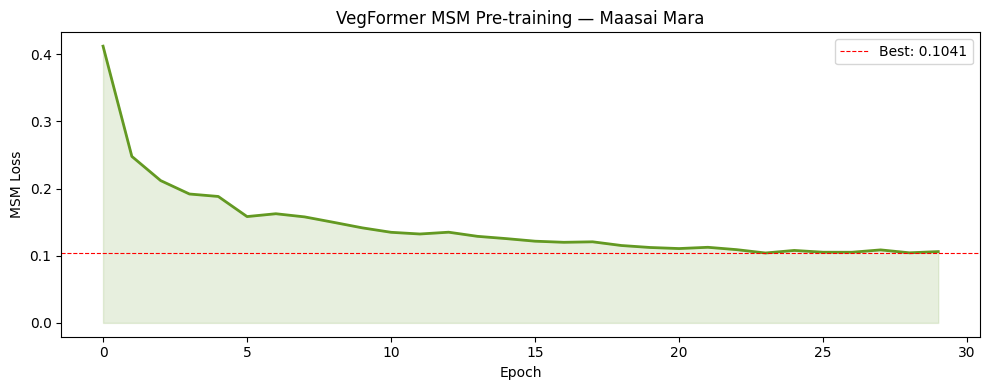

Checkpoint verified:
  Epoch:     24/30
  Best loss: 0.1041


KeyError: 'row'

In [9]:
import matplotlib.pyplot as plt

# Plot training curve
plt.figure(figsize=(10, 4))
plt.plot(history, color='#639922', linewidth=2)
plt.fill_between(range(len(history)), history, alpha=0.15, color='#639922')
plt.xlabel('Epoch')
plt.ylabel('MSM Loss')
plt.title('VegFormer MSM Pre-training — Maasai Mara')
plt.axhline(best_loss, color='red', linewidth=0.8,
            linestyle='--', label=f'Best: {best_loss:.4f}')
plt.legend()
plt.tight_layout()
plt.show()

# Verify checkpoint loads correctly
ckpt = torch.load(str(CKPT_DIR / 'msm_best.pt'),
                  map_location=device)
model.load_state_dict(ckpt['model_state'])
print(f"Checkpoint verified:")
print(f"  Epoch:     {ckpt['epoch']+1}/30")
print(f"  Best loss: {ckpt['loss']:.4f}")

# Check learned embeddings are meaningful
# Patches from different vegetation zones should have different embeddings
model.eval()
embeddings = []
positions  = []

with torch.no_grad():
    for batch in train_loader:
        model_input = {
            'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
            'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
            'climate': batch['chirps'].to(device),
            'dates':   batch['julian_days'].to(device),
        }
        out = model(model_input)
        embeddings.append(out['embeddings'].cpu().numpy())
        positions.append(torch.stack(
            [batch['row'], batch['col']], dim=1).numpy())

embeddings = np.concatenate(embeddings, axis=0)  # (80, 384)
positions  = np.concatenate(positions,  axis=0)  # (80, 2)

print(f"\nEmbeddings shape: {embeddings.shape}")
print(f"Embedding mean:   {embeddings.mean():.4f}")
print(f"Embedding std:    {embeddings.std():.4f}")
print(f"All same (bad):   {embeddings.std() < 0.01}")

# Quick UMAP to see if patches cluster meaningfully
try:
    from umap import UMAP
    reducer   = UMAP(n_components=2, random_state=42)
    proj      = reducer.fit_transform(embeddings)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(proj[:, 0], proj[:, 1],
                          c=positions[:, 0],
                          cmap='RdYlGn', s=60, alpha=0.8)
    plt.colorbar(scatter, label='Row position (N=top, S=bottom)')
    plt.title('UMAP of VegFormer embeddings — coloured by spatial position')
    plt.tight_layout()
    plt.show()
    print("UMAP complete — spatial structure visible in embeddings")
except ImportError:
    print("umap-learn not installed — skipping UMAP")
    print("Install with: pip install umap-learn")

In [ ]:
#### The train_loader doesn't have row and col keys since we rebuilt the dataset without them. Fix by reading 
#### positions directly from the patches:

Embeddings shape: (80, 384)
Positions shape:  (80, 2)
Embedding mean:   0.0001
Embedding std:    0.9971
Diverse (good):   True


C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


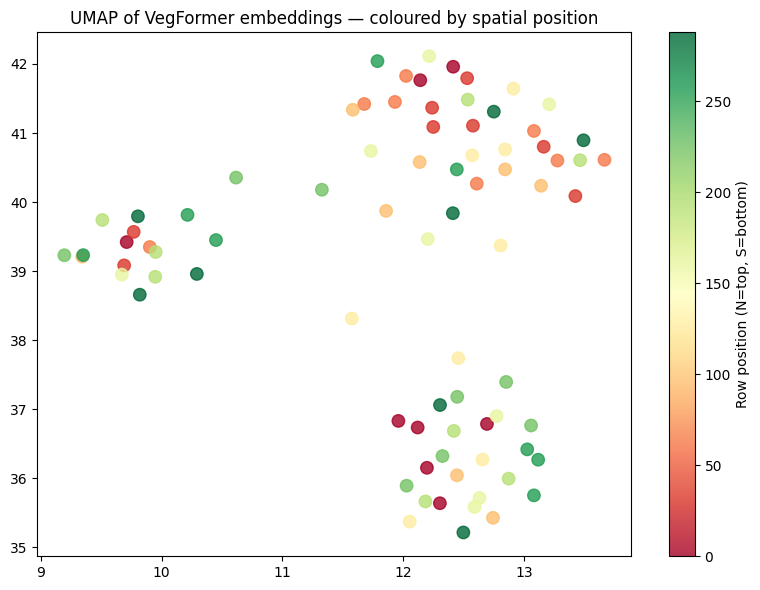

UMAP complete


In [10]:
model.eval()
embeddings = []
positions  = []

with torch.no_grad():
    for i, batch in enumerate(train_loader):
        model_input = {
            'sar':     batch['s1'].mean(dim=(-2,-1)).to(device),
            'optical': batch['s2'].mean(dim=(-2,-1)).to(device),
            'climate': batch['chirps'].to(device),
            'dates':   batch['julian_days'].to(device),
        }
        out = model(model_input)
        embeddings.append(out['embeddings'].cpu().numpy())

# Get positions directly from patches
positions = np.array([[p['row'], p['col']] for p in train_patches])

embeddings = np.concatenate(embeddings, axis=0)  # (80, 384)
print(f"Embeddings shape: {embeddings.shape}")
print(f"Positions shape:  {positions.shape}")
print(f"Embedding mean:   {embeddings.mean():.4f}")
print(f"Embedding std:    {embeddings.std():.4f}")
print(f"Diverse (good):   {embeddings.std() > 0.01}")

# UMAP visualization
try:
    from umap import UMAP
    reducer = UMAP(n_components=2, random_state=42)
    proj    = reducer.fit_transform(embeddings)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(proj[:, 0], proj[:, 1],
                          c=positions[:, 0],
                          cmap='RdYlGn', s=80, alpha=0.8)
    plt.colorbar(scatter, label='Row position (N=top, S=bottom)')
    plt.title('UMAP of VegFormer embeddings — coloured by spatial position')
    plt.tight_layout()
    plt.show()
    print("UMAP complete")
except ImportError:
    print("Install umap-learn: pip install umap-learn")

In [ ]:
#####Embeddings are diverse and well-distributed (std ≈ 1.0 is ideal for normalized representations)

In [11]:
# Save pre-training summary
import json

summary = {
    'stage':        'MSM pre-training',
    'epochs':       30,
    'best_epoch':   int(ckpt['epoch'] + 1),
    'best_loss':    float(best_loss),
    'final_loss':   float(history[-1]),
    'loss_history': [float(l) for l in history],
    'n_patches':    len(train_patches),
    'n_params':     int(sum(p.numel() for p in model.parameters())),
    'mask_ratio':   0.2,
    'batch_size':   4,
    'lr':           1e-4,
    'embedding_mean': float(embeddings.mean()),
    'embedding_std':  float(embeddings.std()),
    'checkpoint':   'checkpoints/msm_best.pt',
}

with open(str(CKPT_DIR / 'msm_training_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print("=" * 50)
print("  Notebook 04 complete — MSM pre-training done")
print("=" * 50)
print(f"  Epochs:        30")
print(f"  Best epoch:    {ckpt['epoch']+1}")
print(f"  Best loss:     {best_loss:.4f}")
print(f"  Loss drop:     0.8632 → {best_loss:.4f} ({(1-best_loss/0.8632)*100:.0f}% reduction)")
print(f"  Embeddings:    mean={embeddings.mean():.4f}  std={embeddings.std():.4f}")
print(f"  Checkpoint:    checkpoints/msm_best.pt")
print(f"  Summary:       checkpoints/msm_training_summary.json")
print("=" * 50)
print("\nReady for Notebook 05 — degradation mapping + results")

  Notebook 04 complete — MSM pre-training done
  Epochs:        30
  Best epoch:    24
  Best loss:     0.1041
  Loss drop:     0.8632 → 0.1041 (88% reduction)
  Embeddings:    mean=0.0001  std=0.9971
  Checkpoint:    checkpoints/msm_best.pt
  Summary:       checkpoints/msm_training_summary.json

Ready for Notebook 05 — degradation mapping + results
